## Working on COVID-19 dataset with python 

#### COVID-19 SMALL DATASET

##### The data is available as a CSV File.

##### The data is used is till 29-April-2020 and has records as on 29-April-2020.

##### We will analyze this data using the pandas DataFrame.

In [3]:
import pandas as pd
import numpy as np

In [4]:
df=pd.read_csv('covid.csv')

In [5]:
df

,Date,State,Region,Confirmed,Deaths,Recovered
0,4/29/2020,NaN,Afghanistan,1939,60,252
1,4/29/2020,NaN,Albania,766,30,455
2,4/29/2020,NaN,Algeria,3848,444,1702
3,4/29/2020,NaN,Andorra,743,42,423
4,4/29/2020,NaN,Angola,27,2,7
...,...,...,...,...,...,...
316,4/29/2020,Wyoming,US,545,7,0
317,4/29/2020,Xinjiang,Mainland China,76,3,73
318,4/29/2020,Yukon,Canada,11,0,0
319,4/29/2020,Yunnan,Mainland China,185,2,181


### Exploring data 

In [7]:
df.shape

(321, 6)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 321 entries, 0 to 320
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Date       321 non-null    object
 1   State      140 non-null    object
 2   Region     321 non-null    object
 3   Confirmed  321 non-null    int64 
 4   Deaths     321 non-null    int64 
 5   Recovered  321 non-null    int64 
dtypes: int64(3), object(3)
memory usage: 15.2+ KB


In [11]:
df.count()

Date         321
State        140
Region       321
Confirmed    321
Deaths       321
Recovered    321
dtype: int64

In [13]:
df.isnull().sum()

Date           0
State        181
Region         0
Confirmed      0
Deaths         0
Recovered      0
dtype: int64

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

#### plotting heatmap to show the null values

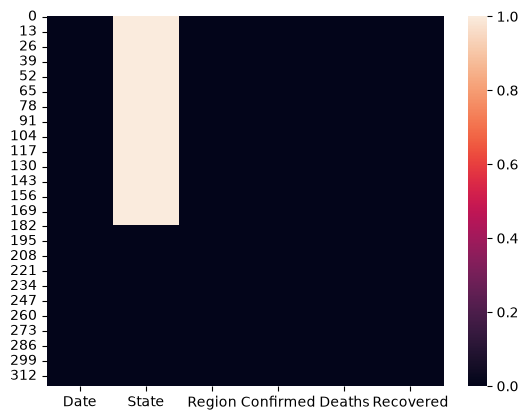

In [16]:
sns.heatmap(df.isnull())
plt.show()

### 1. Show the number of Confirmed , Deaths and Recovered cases in each Region 

In [18]:
df.head()

,Date,State,Region,Confirmed,Deaths,Recovered
0,4/29/2020,NaN,Afghanistan,1939,60,252
1,4/29/2020,NaN,Albania,766,30,455
2,4/29/2020,NaN,Algeria,3848,444,1702
3,4/29/2020,NaN,Andorra,743,42,423
4,4/29/2020,NaN,Angola,27,2,7


In [20]:
df.groupby('Region').sum()                         # groupby on Region column >> makes the group of each unique value present in any column

,Date,State,Confirmed,Deaths,Recovered
Region,,,,,
Afghanistan,4/29/2020,0,1939,60,252
Albania,4/29/2020,0,766,30,455
Algeria,4/29/2020,0,3848,444,1702
Andorra,4/29/2020,0,743,42,423
Angola,4/29/2020,0,27,2,7
...,...,...,...,...,...
West Bank and Gaza,4/29/2020,0,344,2,71
Western Sahara,4/29/2020,0,6,0,5
Yemen,4/29/2020,0,6,0,1


In [30]:
df.groupby('Region')['Confirmed'].sum().sort_values(ascending=False).head(10)

Region
US                1039909
Spain              236899
Italy              203591
France             166543
UK                 166441
Germany            161539
Turkey             117589
Russia              99399
Iran                93657
Mainland China      82862
Name: Confirmed, dtype: int64

In [99]:
df.groupby('Region')[['Confirmed','Recovered','Deaths']].sum() 

,Confirmed,Recovered,Deaths
Region,,,
Afghanistan,1939,252,60
Albania,766,455,30
Algeria,3848,1702,444
Andorra,743,423,42
Angola,27,7,2
...,...,...,...
Venezuela,331,142,10
Vietnam,270,222,0
West Bank and Gaza,344,71,2


### 2. Remove all the records where Confirmed Cases is less than 10. 

In [38]:
df.head(5)

,Date,State,Region,Confirmed,Deaths,Recovered
0,4/29/2020,NaN,Afghanistan,1939,60,252
1,4/29/2020,NaN,Albania,766,30,455
2,4/29/2020,NaN,Algeria,3848,444,1702
3,4/29/2020,NaN,Andorra,743,42,423
4,4/29/2020,NaN,Angola,27,2,7


In [39]:
df['Confirmed']<10

0      False
1      False
2      False
3      False
4      False
       ...  
316    False
317    False
318    False
319    False
320    False
Name: Confirmed, Length: 321, dtype: bool

In [44]:
df=df[~(df.Confirmed<10)]       # to remove the records 

In [51]:
df

,Date,State,Region,Confirmed,Deaths,Recovered
0,4/29/2020,NaN,Afghanistan,1939,60,252
1,4/29/2020,NaN,Albania,766,30,455
2,4/29/2020,NaN,Algeria,3848,444,1702
3,4/29/2020,NaN,Andorra,743,42,423
4,4/29/2020,NaN,Angola,27,2,7
...,...,...,...,...,...,...
316,4/29/2020,Wyoming,US,545,7,0
317,4/29/2020,Xinjiang,Mainland China,76,3,73
318,4/29/2020,Yukon,Canada,11,0,0
319,4/29/2020,Yunnan,Mainland China,185,2,181


### 3. In which Reigion , maximum number of Confirmed cases were recorded.

In [61]:
df.head()

,Date,State,Region,Confirmed,Deaths,Recovered
0,4/29/2020,NaN,Afghanistan,1939,60,252
1,4/29/2020,NaN,Albania,766,30,455
2,4/29/2020,NaN,Algeria,3848,444,1702
3,4/29/2020,NaN,Andorra,743,42,423
4,4/29/2020,NaN,Angola,27,2,7


In [100]:
df.groupby('Region')['Confirmed'].sum().sort_values(ascending=False).head(1)

Region
US    1039909
Name: Confirmed, dtype: int64

### 4. In which Region , minimum  number of Deaths cases were recorded.

In [1]:
df.groupby('Region').Deaths.sum().sort_values(ascending=True).head(30)

NameError: name 'df' is not defined

### 5. How many Confirmed , Deaths & Recovered cases were reported from india till 29 April 2020.

In [69]:
df.head()

,Date,State,Region,Confirmed,Deaths,Recovered
0,4/29/2020,NaN,Afghanistan,1939,60,252
1,4/29/2020,NaN,Albania,766,30,455
2,4/29/2020,NaN,Algeria,3848,444,1702
3,4/29/2020,NaN,Andorra,743,42,423
4,4/29/2020,NaN,Angola,27,2,7


In [71]:
df[df.Region=='India']

,Date,State,Region,Confirmed,Deaths,Recovered
74,4/29/2020,NaN,India,33062,1079,8437


### 6. what is the total number of recovered patients in each region .

In [74]:
df.groupby('Region')['Recovered'].sum().sort_values(ascending=False)

Region
Spain             132929
Germany           120400
Mainland China     77609
Iran               73791
Italy              71252
                   ...  
Cabo Verde             2
Holy See               2
Canada                 0
South Sudan            0
US                     0
Name: Recovered, Length: 180, dtype: int64

### 7. Display all rows where the number of deaths is Zero.

In [75]:
df[df['Deaths']==0]

,Date,State,Region,Confirmed,Deaths,Recovered
29,4/29/2020,NaN,Cambodia,122,0,119
31,4/29/2020,NaN,Central African Republic,50,0,10
45,4/29/2020,NaN,Dominica,16,0,13
51,4/29/2020,NaN,Eritrea,39,0,19
55,4/29/2020,NaN,Fiji,18,0,12
64,4/29/2020,NaN,Grenada,20,0,13
70,4/29/2020,NaN,Holy See,10,0,2
90,4/29/2020,NaN,Laos,19,0,7
99,4/29/2020,NaN,Madagascar,128,0,90
110,4/29/2020,NaN,Mongolia,38,0,10
